---
numbering: false
---

# 5.3: Subspaces, bases, dimension, and rank

As we've seen in [Chapter 5.1](05-01.ipynb) and [Chapter 5.2](05-02.ipynb), the outputs of a matrix $A$ form a set of vectors called its **column space**, $\operatorname{colsp}(A)$.

We've seen that the column space of a matrix with 2 rows might be a line or all of $\mathbb R^2$, and that the column space of a matrix with 3 rows might be a line, a plane, or all of $\mathbb R^3$. But how do we describe the column space of a matrix with more than 3 rows?

---

## Subspaces

Lines and planes are both "flat" objects that extend infinitely, without edges, in their directions. A line, whether it is in $\mathbb R^2$, $\mathbb R^3$, or $\mathbb R^{17}$ for that matter, is 1-dimensional in some sense and can be thought of as a "slice" of space. Similarly, a plane in $\mathbb R^3$ is a 2-dimensional "slice."

The general notion of a "flat slice" **through the origin** is more precisely referred to as a **subspace**.

:::{note} Definition: Subspace
A subset $S$ of $\mathbb R^n$ is a **subspace of $\mathbb R^n$** if:

1. $\vec0\in S$.
2. If $\vec u,\vec v\in S$, then $\vec u+\vec v\in S$. We say $S$ is **closed under addition**.
3. If $\vec u\in S$ and $c\in\mathbb R$, then $c\vec u\in S$. We say $S$ is **closed under scalar multiplication**.
:::

Imagine a subspace as a gated community of vectors, where linear combinations cannot escape the community. These conditions must hold for every vector in the set and every real scalar. One counterexample is enough to show that a set is not a subspace.


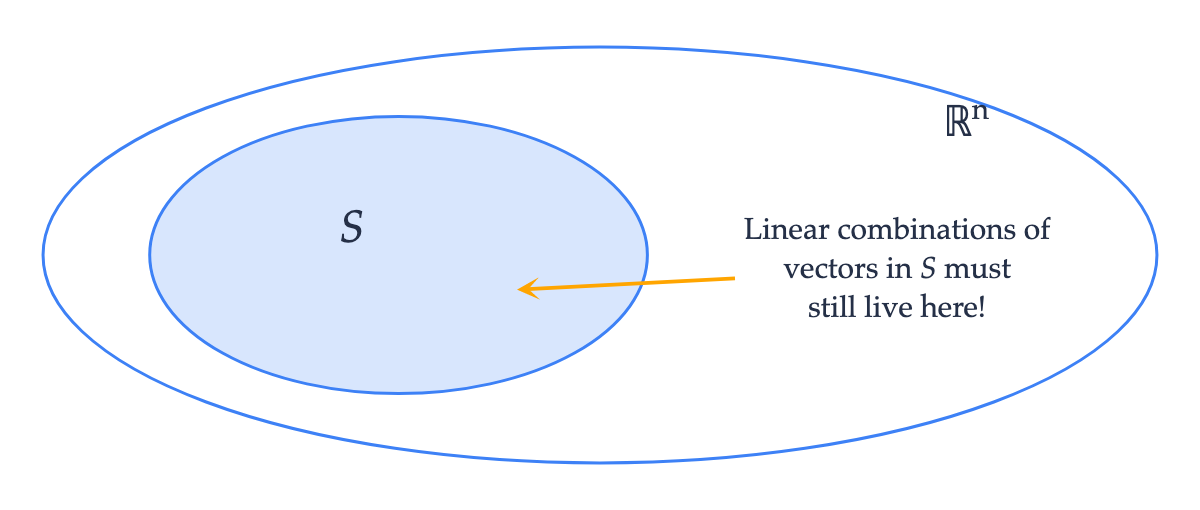

In [1]:
import plotly.graph_objects as go
from IPython.display import Image, display

# A set-containment schematic: the ovals do not depict the geometry of a subspace.
fig = go.Figure()
fig.add_shape(type='circle', x0=.03, y0=.08, x1=.97, y1=.92,
              line=dict(color='#3d81f6', width=2), fillcolor='white')
fig.add_shape(type='circle', x0=.12, y0=.22, x1=.54, y1=.78,
              line=dict(color='#3d81f6', width=2), fillcolor='rgba(61,129,246,.20)')
fig.add_annotation(x=.81, y=.77, text='ℝ<sup>n</sup>', showarrow=False,
                   font=dict(size=28, color='#253047'))
fig.add_annotation(x=.29, y=.55, text='<i>S</i>', showarrow=False,
                   font=dict(size=30, color='#253047'))
fig.add_annotation(x=.43, y=.43, ax=.75, ay=.47,
                   xref='x', yref='y', axref='x', ayref='y',
                   text='Linear combinations of<br>vectors in <i>S</i> must<br>still live here!',
                   showarrow=True, arrowhead=3, arrowwidth=2.5,
                   arrowcolor='orange', font=dict(size=20, color='#253047'),
                   bgcolor='white', borderpad=5, align='center')
fig.update_layout(width=800, height=340, margin=dict(l=5,r=5,t=5,b=5),
                   paper_bgcolor='white', plot_bgcolor='white',
                   font=dict(family='Palatino, Palatino Linotype, serif'),
                   xaxis=dict(range=[0,1],visible=False,fixedrange=True),
                   yaxis=dict(range=[0,1],visible=False,fixedrange=True))
display(Image(fig.to_image(format='png',scale=1.5)))


### Examples and non-examples

Below, we've shown 4 examples of **subsets** of $\mathbb R^2$ in blue. Orange vectors belong to the set, while pink vectors (for the sets that are **not subspaces**) show a violation of one of the subspace properties. The pink cross marks the missing zero vector.


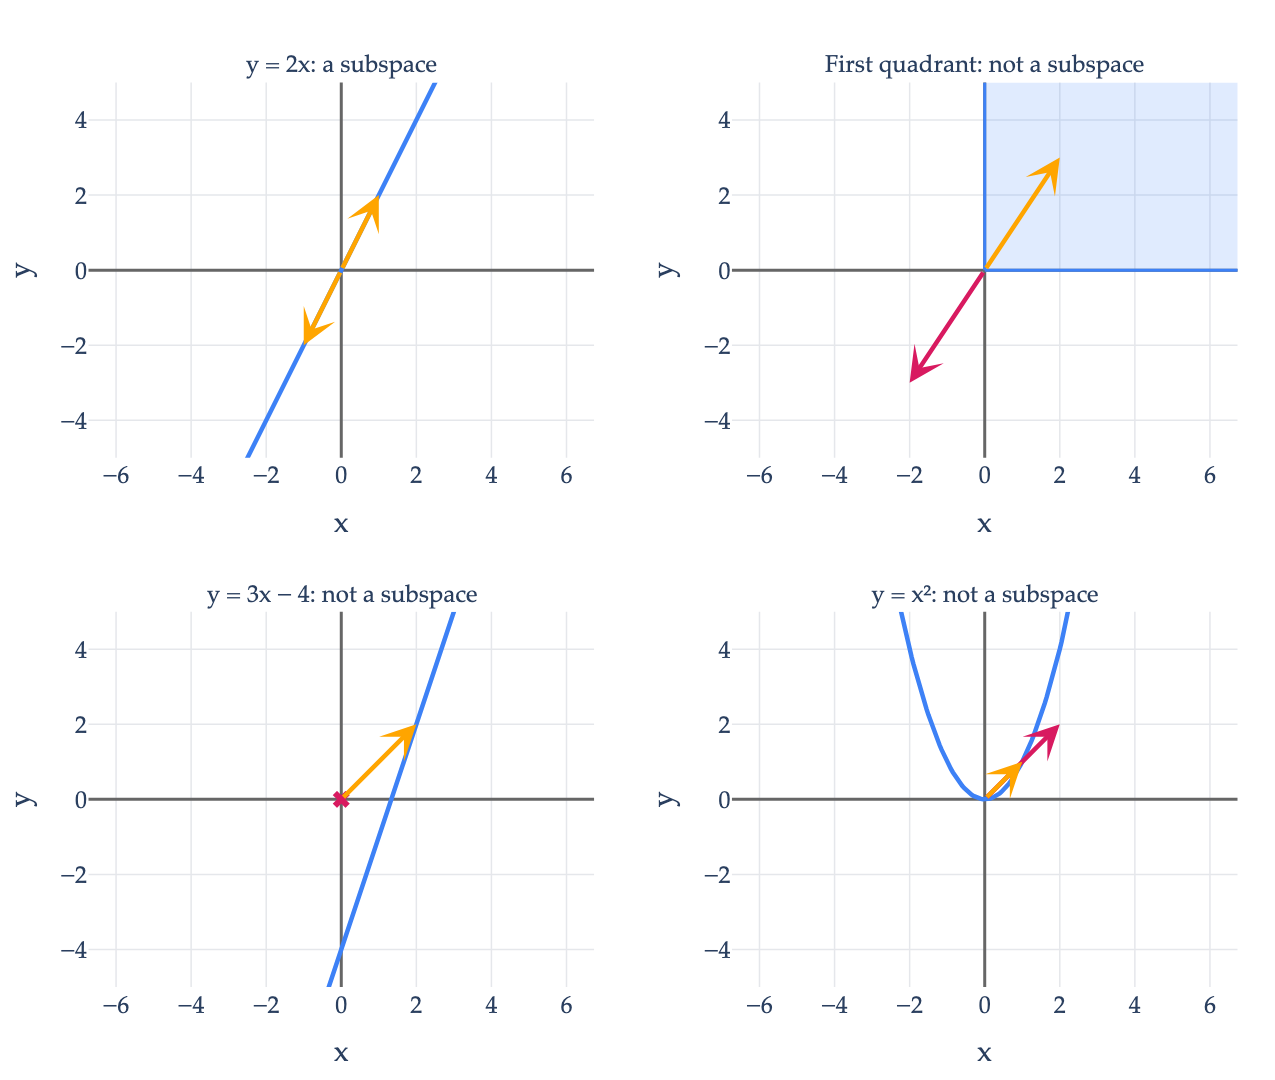

In [2]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import Image, display

blue, orange, pink = '#3d81f6', 'orange', '#d81a60'
fig = make_subplots(rows=2, cols=2, subplot_titles=[
    'y = 2x: a subspace', 'First quadrant: not a subspace',
    'y = 3x − 4: not a subspace', 'y = x²: not a subspace'],
    horizontal_spacing=.12, vertical_spacing=.17)
x = np.linspace(-4,4,161)
fig.add_trace(go.Scatter(x=x,y=2*x,mode='lines',line=dict(color=blue,width=3)),row=1,col=1)
fig.add_trace(go.Scatter(x=[0,20,20,0,0],y=[0,0,20,20,0],mode='lines',fill='toself',fillcolor='rgba(61,129,246,0.16)',line=dict(color=blue,width=2)),row=1,col=2)
fig.add_trace(go.Scatter(x=x,y=3*x-4,mode='lines',line=dict(color=blue,width=3)),row=2,col=1)
fig.add_trace(go.Scatter(x=x,y=x*x,mode='lines',line=dict(color=blue,width=3)),row=2,col=2)
# Vectors in each set and counterexamples to closure.
for row,col,px,py,color in [(1,1,1,2,orange),(1,1,-1,-2,orange),(1,2,2,3,orange),(1,2,-2,-3,pink),(2,1,2,2,orange),(2,2,2,2,pink),(2,2,1,1,orange)]:
    axis=(row-1)*2+col
    suffix=str(axis) if axis>1 else ''
    fig.add_annotation(x=px,y=py,ax=0,ay=0,xref='x'+suffix,yref='y'+suffix,
                       axref='x'+suffix,ayref='y'+suffix,text='',showarrow=True,
                       arrowhead=3,arrowsize=1.3,arrowwidth=3,arrowcolor=color)
# The zero vector has no direction or length, so mark the missing origin.
fig.add_trace(go.Scatter(x=[0],y=[0],mode='markers',marker=dict(size=10,color=pink,symbol='x')),row=2,col=1)
for row in [1,2]:
    for col in [1,2]:
        axis=(row-1)*2+col
        fig.update_xaxes(range=[-4,4],title_text='x',dtick=2,gridcolor='#e5e7eb',zerolinecolor='#666',row=row,col=col)
        fig.update_yaxes(range=[-5,5],title_text='y',dtick=2,gridcolor='#e5e7eb',zerolinecolor='#666',scaleanchor='x'+(str(axis) if axis>1 else ''),scaleratio=1,row=row,col=col)
fig.update_layout(width=850,height=720,showlegend=False,paper_bgcolor='white',plot_bgcolor='white',font=dict(family='Palatino, Palatino Linotype, serif',size=16),margin=dict(l=45,r=25,t=55,b=40))
display(Image(fig.to_image(format='png',scale=1.5)))


- The line $y=2x$ **is a subspace**. Its vectors have the form $\begin{bmatrix}a\\2a\end{bmatrix}$. It contains $\vec0$, and

  $$\begin{bmatrix}a\\2a\end{bmatrix}+\begin{bmatrix}b\\2b\end{bmatrix}=\begin{bmatrix}a+b\\2(a+b)\end{bmatrix},\qquad
  c\begin{bmatrix}a\\2a\end{bmatrix}=\begin{bmatrix}ca\\2ca\end{bmatrix}$$

  are still on the line.

- The first quadrant, where $x\ge0$ and $y\ge0$, **is not a subspace**. It contains $\begin{bmatrix}2\\3\end{bmatrix}$ but not $-\begin{bmatrix}2\\3\end{bmatrix}=\begin{bmatrix}-2\\-3\end{bmatrix}$. It fails closure under scalar multiplication.

- The line $y=3x-4$ **is not a subspace**. It misses the origin: $0\ne3(0)-4$. It is an **affine subspace**—a shifted subspace. Being flat is not enough.

- The parabola $y=x^2$, written in set-builder notation as

  $$S=\left\{\begin{bmatrix}x\\y\end{bmatrix}\in\mathbb R^2:y=x^2\right\},$$

  **is not a subspace**. It contains $\begin{bmatrix}1\\1\end{bmatrix}$, but doubling this vector gives $\begin{bmatrix}2\\2\end{bmatrix}$, which is not on the parabola. This fails closure under both scalar multiplication and addition. Passing through the origin is not enough either.

The possible subspaces in $\mathbb R^2$ and $\mathbb R^3$ are:

| Space | All possible types of subspaces |
| --- | --- |
| $\mathbb R^2$ | $\{\vec0\}$, lines through the origin, all of $\mathbb R^2$ |
| $\mathbb R^3$ | $\{\vec0\}$, lines through the origin, planes through the origin, all of $\mathbb R^3$ |

::::{tip} Activity 1

Let $S$ be the set of vectors on either coordinate axis in $\mathbb R^2$:

$$S=\left\{\begin{bmatrix}x\\y\end{bmatrix}\in\mathbb R^2:x=0\text{ or }y=0\right\}.$$

Which subspace conditions hold? Which fail?

:::{tip} Solution
:class: dropdown

The set contains $\vec0$, and scaling a vector on an axis keeps it on that axis. But it is not closed under addition:

$$\begin{bmatrix}2\\0\end{bmatrix}+\begin{bmatrix}0\\3\end{bmatrix}=\begin{bmatrix}2\\3\end{bmatrix}.$$

The two summands are in $S$; their sum is not. So $S$ is not a subspace.
:::
::::


### Spans and column spaces

Subspaces generalize lines and planes through the origin, which we already know how to describe as spans of one or two vectors. Here's the key connection: **Every span of vectors in $\mathbb R^n$ is a subspace of $\mathbb R^n$.** In particular, $\operatorname{colsp}(A)$ for an $n\times d$ matrix $A$ is a subspace of $\mathbb R^n$.

For example, revisit the matrices from [Chapter 5.1](05-01.ipynb):

- For $A=\begin{bmatrix}1&0\\1&1\\0&1\end{bmatrix}$, $\operatorname{colsp}(A)$ is a subspace of $\mathbb R^3$: the plane $x-y+z=0$.
- Adding the redundant column in $B$ leaves that plane unchanged, so $\operatorname{colsp}(B)$ is the same subspace.
- The three independent columns of $C$ span all of $\mathbb R^3$, which is itself a subspace of $\mathbb R^3$.


---

## Bases

Consider the $4\times3$ matrix

$$A=\begin{bmatrix}|&|&|\\\vec a_1&\vec a_2&\vec a_3\\|&|&|\end{bmatrix}
=\begin{bmatrix}1&0&1\\2&-1&5\\0&1&-3\\-1&3&-10\end{bmatrix}.$$

Its column space is a subspace of $\mathbb R^4$, since its columns have four entries. But we don't need all three columns to describe $\operatorname{colsp}(A)$, because its third column is redundant:

$$\vec a_3=\vec a_1-3\vec a_2.$$

Removing $\vec a_3$ leaves the column space unchanged. Indeed,

$$A\begin{bmatrix}p\\q\\r\end{bmatrix}=(p+r)\vec a_1+(q-3r)\vec a_2,$$

and every combination of $\vec a_1,\vec a_2$ is an output by choosing $r=0$. These two columns span the column space and are independent, since neither is a scalar multiple of the other.

We say $\{\vec a_1,\vec a_2\}$ form a **basis** for $\operatorname{colsp}(A)$.

:::{note} Definition: Basis
A **basis** of a subspace is a collection of linearly independent vectors that spans the subspace.
:::

The plural of **basis** is **bases**. Every nonzero subspace has infinitely many bases. Here are some examples and non-examples of bases for $\operatorname{colsp}(A)$, where

$$A=\begin{bmatrix}1&0&1\\2&-1&5\\0&1&-3\\-1&3&-10\end{bmatrix}.$$

| Collection | Is it a basis of $\operatorname{colsp}(A)$? |
| --- | --- |
| $\{\vec a_1\}$ | **No**: independent, but spans only a line. |
| $\{\vec a_1,\vec a_2\}$ | **Yes**: independent and spans the whole column space. |
| $\{\vec a_1,7\vec a_1\}$ | **No**: dependent and spans only a line. |
| $\{\vec a_2,\vec a_3\}$ | **Yes**: independent, and $\vec a_1=\vec a_3+3\vec a_2$ recovers the remaining column. |
| $\{\vec a_1,\vec a_2,\vec a_3\}$ | **No**: spans the column space, but is dependent. |
| $\{\vec a_1,\vec a_1+\vec a_2\}$ | **Yes**: independent, and subtracting its first vector from its second recovers $\vec a_2$. |

The last collection shows that a basis need not use the original matrix's columns.

::::{tip} Activity 2
Let $\vec u,\vec v,\vec w$ be the columns of

$$G=\begin{bmatrix}1&0&1\\0&2&2\\2&1&3\end{bmatrix}.$$

1. Find a basis of $\operatorname{colsp}(G)$ using columns of $G$.
2. Is $\{\vec u+\vec v,\vec u-\vec v\}$ also a basis? Explain.
3. Is $\{\vec u+\vec v,2\vec u+2\vec v\}$ a basis? Explain.

:::{tip} Solution
:class: dropdown

**1.** $\vec w=\vec u+\vec v$, so $\vec u,\vec v$ span the column space. They are not scalar multiples, so $\{\vec u,\vec v\}$ is a basis.

**2.** Yes. We can recover the original basis vectors:

$$\vec u=\tfrac12[(\vec u+\vec v)+(\vec u-\vec v)],\qquad
\vec v=\tfrac12[(\vec u+\vec v)-(\vec u-\vec v)].$$

Thus the new pair spans the same subspace. The vectors $\begin{bmatrix}1\\2\\3\end{bmatrix}$ and $\begin{bmatrix}1\\-2\\1\end{bmatrix}$ are not scalar multiples, so they are independent.

**3.** No. The second vector is twice the first. They are dependent and span only a line.
:::
::::

---

## Dimension

Different bases of a subspace can use different vectors, but they always contain the same number of vectors.

:::{note} Definition: Dimension
The **dimension** of a subspace $S$, denoted $\dim(S)$, is the number of vectors in a basis of $S$.
:::

For our $4\times3$ matrix

$$A=\begin{bmatrix}1&0&1\\2&-1&5\\0&1&-3\\-1&3&-10\end{bmatrix},$$

the basis $\{\vec a_1,\vec a_2\}$ contains two vectors. Thus $\dim(\operatorname{colsp}(A))=2$: its column space is a plane through the origin in $\mathbb R^4$.

These are three different counts: **4 rows** tell us that outputs have four entries; **3 columns** tell us that inputs have three entries; **dimension 2** tells us how many vectors a basis contains.

A line has dimension 1, regardless of how many entries its vectors have. For example,

$$\left\{t\begin{bmatrix}2\\-1\\0\\3\\1\end{bmatrix}:t\in\mathbb R\right\}$$

is a line in $\mathbb R^5$, with the displayed nonzero vector as a basis.

The columns of $I_n$ form the **standard basis** of $\mathbb R^n$: they are independent, and any vector is their linear combination with its entries as coefficients. Hence $\dim(\mathbb R^n)=n$. By convention, the empty collection is a basis of $\{\vec0\}$, which has dimension zero.


For example, **3 linearly independent vectors in $\mathbb R^3$ must form a basis of $\mathbb R^3$ and span all of $\mathbb R^3$**. Since $\mathbb R^3$ has dimension 3, an independent collection of 3 vectors already has as many vectors as a basis; it cannot span a smaller subspace.

### Example: A basis from equations

Consider the set

$$S=\left\{\begin{bmatrix}x_1\\x_2\\x_3\\x_4\end{bmatrix}\in\mathbb R^4:x_1+x_2=0,\ x_3=2x_4\right\}.$$

What does this set look like? The equations force $x_2=-x_1$ and $x_3=2x_4$. Choose $x_1=s$ and $x_4=t$. Then

$$\begin{bmatrix}x_1\\x_2\\x_3\\x_4\end{bmatrix}
=\begin{bmatrix}s\\-s\\2t\\t\end{bmatrix}
=s\begin{bmatrix}1\\-1\\0\\0\end{bmatrix}+t\begin{bmatrix}0\\0\\2\\1\end{bmatrix}.$$

Every vector in $S$ has this form, and every choice of $s,t$ satisfies both equations. Thus $S$ is the span of the two displayed vectors, so it is a subspace. Neither vector is a scalar multiple of the other, so they form a basis. Therefore $\dim(S)=2$: it is a plane through the origin in $\mathbb R^4$.

---

## Rank and solvability

:::{note} Definition: Rank
The **rank** of a matrix $A$ is the dimension of its column space:

$$\operatorname{rank}(A)=\dim(\operatorname{colsp}(A)).$$
:::

Equivalently, rank is the maximum number of linearly independent columns. Our $4\times3$ matrix $A$ has rank 2.

Here are several examples of matrices and their ranks; we have already seen many of these matrices in this chapter.

| Matrix | Rank | Explanation |
| --- | --- | --- |
| $\begin{bmatrix}1&0&1\\2&-1&5\\0&1&-3\\-1&3&-10\end{bmatrix}$ | $2$ | The first two columns are independent; the third is the first minus three times the second. |
| $\begin{bmatrix}1&0\\1&1\\0&1\end{bmatrix}$ | $2$ | Its two columns are independent. |
| $\begin{bmatrix}1&0&2\\1&1&1\\0&1&-1\end{bmatrix}$ | $2$ | The third column is twice the first minus the second; the first two are independent. |
| $\begin{bmatrix}1&0&2\\1&1&4\\0&1&3\end{bmatrix}$ | $3$ | The first two columns span $x-y+z=0$; the third lies outside that plane. |
| $\begin{bmatrix}1&0&2&0\\1&1&4&0\\0&1&3&1\end{bmatrix}$ | $3$ | Its first three columns already span $\mathbb R^3$; the fourth cannot enlarge that span. |
| $\begin{bmatrix}0&2&0&0\\-3&0&0&0\\0&0&0&4\\0&0&5&0\end{bmatrix}$ | $4$ | Its columns point along four different coordinate directions. |
| $\begin{bmatrix}2&0&1&0\\0&-3&4&0\\0&0&0&0\\0&0&0&5\end{bmatrix}$ | $3$ | Columns 1, 2, and 4 are independent; column 3 is a combination of columns 1 and 2. |
| $\begin{bmatrix}2&-4\\-1&2\\0&0\\3&-6\\1&-2\end{bmatrix}$ | $1$ | The first column is nonzero and the second is $-2$ times the first. |

As a thought experiment, consider a $7\times10$ matrix. Its smallest possible rank is **0**, achieved by the zero matrix. The largest is **7**: its column space is a subspace of $\mathbb R^7$, so it cannot have dimension larger than 7.

::::{tip} Activity 3

Find a $7\times10$ matrix with rank 7.

:::{tip} Solution
:class: dropdown

One example is

$$\begin{bmatrix}
1&0&0&0&0&0&0&0&0&0\\
0&1&0&0&0&0&0&0&0&0\\
0&0&1&0&0&0&0&0&0&0\\
0&0&0&1&0&0&0&0&0&0\\
0&0&0&0&1&0&0&0&0&0\\
0&0&0&0&0&1&0&0&0&0\\
0&0&0&0&0&0&1&0&0&0
\end{bmatrix}.$$

The first 7 columns are independent, and the last 3 are zero, so this matrix has rank 7.
:::
::::

More generally, a basis chosen from the columns of an $n\times d$ matrix cannot contain more than $d$ vectors, and a subspace of $\mathbb R^n$ cannot have dimension larger than $n$. Therefore,

$$\boxed{0\leq\operatorname{rank}(A)\leq\min(n,d).}$$

### Invertibility

An $n\times n$ matrix is invertible exactly when its $n$ columns are independent, or equivalently, when its rank is $n$. Those columns then form a basis of $\mathbb R^n$.

### Solvability

The equation $A\vec x=\vec b$ has a solution exactly when $\vec b\in\operatorname{colsp}(A)$. If we want a solution for **every** $\vec b\in\mathbb R^n$, the column space must be all of $\mathbb R^n$:

$$\boxed{A\vec x=\vec b\text{ is solvable for every }\vec b\in\mathbb R^n
\quad\Longleftrightarrow\quad\operatorname{rank}(A)=n.}$$

We compare rank to the number of **rows** when asking whether every output is possible. A rectangular matrix can produce every output without being invertible: for example, $\begin{bmatrix}1&0&0\\0&1&0\end{bmatrix}$ has rank 2, but its third input entry can be anything.

As another example, consider

$$F=\begin{bmatrix}1&0&1&-1\\0&1&1&3\\1&1&2&2\end{bmatrix}.$$

The first two columns are independent. The third is their sum, and the fourth is three times the second minus the first. Thus the first two columns form a basis of $\operatorname{colsp}(F)$, and $\operatorname{rank}(F)=2$.

A general combination of the basis vectors is

$$s\begin{bmatrix}1\\0\\1\end{bmatrix}+t\begin{bmatrix}0\\1\\1\end{bmatrix}=\begin{bmatrix}s\\t\\s+t\end{bmatrix}.$$

So $\operatorname{colsp}(F)$ is the plane $z=x+y$. This tells us exactly which outputs are possible. For instance,

$$F\begin{bmatrix}2\\3\\0\\0\end{bmatrix}
=F\begin{bmatrix}1\\2\\1\\0\end{bmatrix}
=\begin{bmatrix}2\\3\\5\end{bmatrix},$$

but $\begin{bmatrix}2\\3\\6\end{bmatrix}$ is impossible. The columns are dependent, so every possible output has infinitely many inputs. Rank 2 describes the dimension of the output set; the plane equation tells us whether a particular vector belongs to it.
